
[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Obtaining dependency information for statsmodels from https://files.pythonhosted.org/packages/03/e3/d863228849da191d37c54bdd72634fbbcfadd12e910e29e4bdca1b952bb6/statsmodels-0.15.0-cp312-cp312-win_amd64.whl.metadata
  Using cached statsmodels-0.15.0-cp312-cp312-win_amd64.whl.metadata (9.6 kB)
  Obtaining dependency information for patsy>=0.5.6 from https://files.pythonhosted.org/packages/20/70/cd3cf5cff538323076a879edef02cce6f13f7d75e03d12f211b0a0dbd178/patsy-1.0.3-py2.py3-none-any.whl.metadata
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Obtaining dependency information for formulaic>=1.1.0 from https://files.pythonhosted.org/packages/fc/75/0576b03f7889ad25b5385b4f6c69e0543713425a6f193b056c9b0a2e65ce/formulaic-1.2.2-py3-none-any.whl.metadata
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Obtaining dependency information for interface-meta>=1.2.0 from https://files.pythonhosted.org/packages/a1/d3/20a61a248feb1249cd81f83ce731f0bdf5170ed96a08a

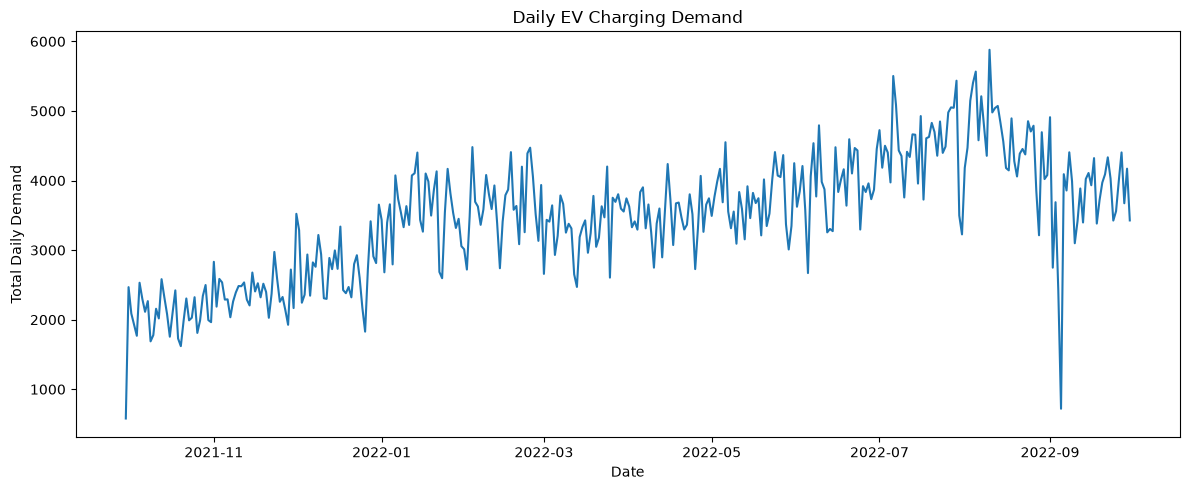

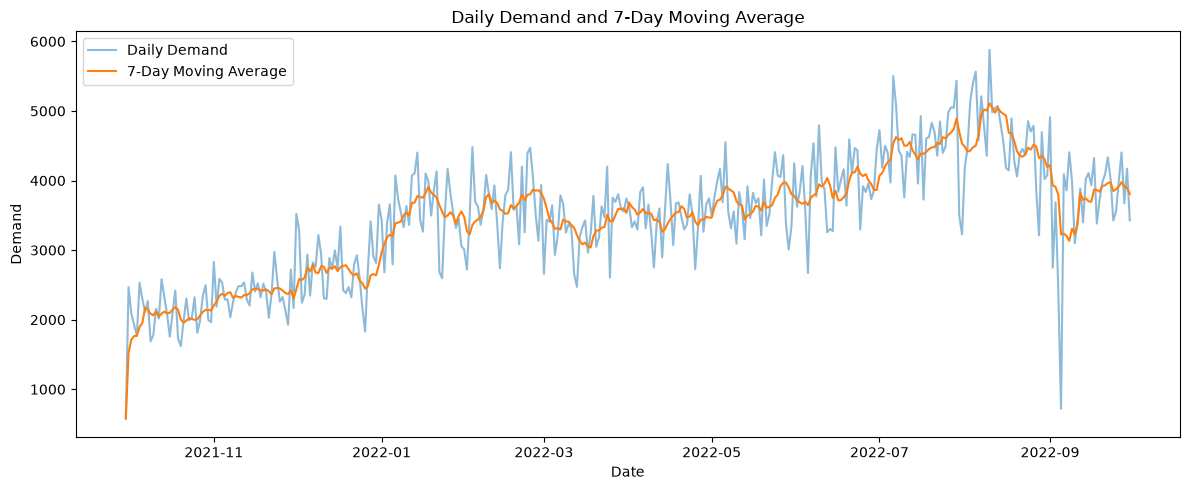

Training days: 292
Testing days: 74

FORECAST EVALUATION
MAE:  570.1388
RMSE: 790.0144


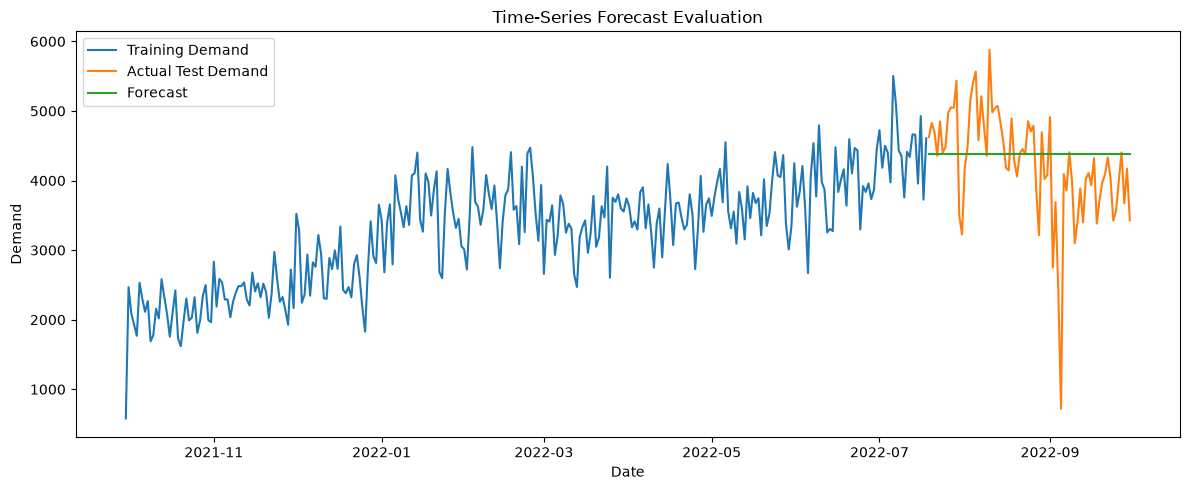


NEXT 7 DAYS FORECAST


,ForecastDemand
2022-10-01,3850.792256
2022-10-02,3850.792256
2022-10-03,3850.792256
2022-10-04,3850.792256
2022-10-05,3850.792256
2022-10-06,3850.792256
2022-10-07,3850.792256


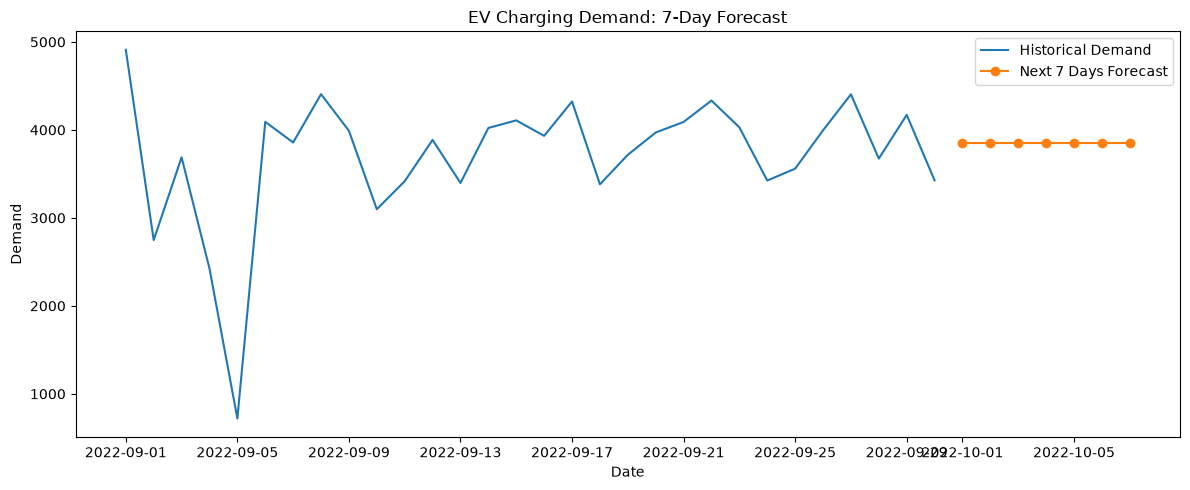


Time-series analysis completed!
Saved: c:\Users\Shyamsekar\OneDrive\Desktop\EV_Charging_Demand_Project\models\forecast_evaluation.csv
Saved: c:\Users\Shyamsekar\OneDrive\Desktop\EV_Charging_Demand_Project\models\seven_day_forecast.csv


In [1]:

# ============================================================
# FILE 4: TIME-SERIES ANALYSIS AND FORECASTING
# ============================================================

%pip install pandas numpy matplotlib statsmodels scikit-learn

# STEP 1: IMPORT LIBRARIES
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# STEP 2: FIND PROJECT FOLDER
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "cleaned_charging_data.csv"
OUTPUT_DIR = ROOT / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# STEP 3: LOAD DATA
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Run File 1 first."
    )

df = pd.read_csv(DATA_PATH)

# STEP 4: CHECK REQUIRED COLUMNS
if "Demand" not in df.columns:
    raise ValueError("Demand column not found.")

if "StartDatetime" not in df.columns:
    raise ValueError(
        "StartDatetime column not found. "
        "Check your dataset's actual date/time column name."
    )

df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="coerce"
)
df["Demand"] = pd.to_numeric(df["Demand"], errors="coerce")

df = df.dropna(
    subset=["StartDatetime", "Demand"]
).copy()

df = df.sort_values("StartDatetime")

# STEP 5: AGGREGATE DEMAND BY DAY
# This assumes summing Demand values is meaningful.
daily = (
    df.set_index("StartDatetime")["Demand"]
    .resample("D")
    .sum(min_count=1)
)

# Fill missing calendar dates only if they truly represent
# zero demand. Otherwise, retain missing values and investigate.
print("Missing daily observations:", daily.isna().sum())

# For this baseline, interpolate internal missing dates.
# Review this assumption before relying on the forecast.
daily = daily.interpolate(limit_area="inside")
daily = daily.dropna()

if len(daily) < 20:
    raise ValueError(
        f"Only {len(daily)} daily observations are available. "
        "Collect more data or use a shorter, carefully justified "
        "evaluation period."
    )

print("Daily observations:", len(daily))
print(daily.head())

# STEP 6: PLOT DAILY DEMAND
plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values)
plt.title("Daily EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Total Daily Demand")
plt.tight_layout()
plt.show()

# STEP 7: PLOT 7-DAY MOVING AVERAGE
rolling_mean = daily.rolling(
    window=7, min_periods=1
).mean()

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily, label="Daily Demand", alpha=0.5)
plt.plot(
    rolling_mean.index,
    rolling_mean,
    label="7-Day Moving Average",
)
plt.title("Daily Demand and 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

# STEP 8: CHRONOLOGICAL TRAIN/TEST SPLIT
split = int(len(daily) * 0.8)

train = daily.iloc[:split]
test = daily.iloc[split:]

print("Training days:", len(train))
print("Testing days:", len(test))

# STEP 9: FIT BASELINE FORECAST MODEL
model = SimpleExpSmoothing(
    train,
    initialization_method="estimated",
).fit()

test_forecast = model.forecast(len(test))

# STEP 10: EVALUATE THE FORECAST
mae = mean_absolute_error(test, test_forecast)
rmse = np.sqrt(mean_squared_error(test, test_forecast))

print("\nFORECAST EVALUATION")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

# STEP 11: PLOT ACTUAL VS PREDICTED
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training Demand")
plt.plot(test.index, test, label="Actual Test Demand")
plt.plot(
    test_forecast.index,
    test_forecast,
    label="Forecast",
)
plt.title("Time-Series Forecast Evaluation")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

# STEP 12: REFIT ON ALL DATA AND FORECAST 7 DAYS
final_model = SimpleExpSmoothing(
    daily,
    initialization_method="estimated",
).fit()

future_forecast = final_model.forecast(7)

print("\nNEXT 7 DAYS FORECAST")
display(future_forecast.to_frame(name="ForecastDemand"))

# STEP 13: PLOT FUTURE FORECAST
future_dates = pd.date_range(
    start=daily.index[-1] + pd.Timedelta(days=1),
    periods=7,
    freq="D",
)

plt.figure(figsize=(12, 5))
plt.plot(
    daily.tail(30).index,
    daily.tail(30),
    label="Historical Demand",
)
plt.plot(
    future_dates,
    future_forecast.values,
    marker="o",
    label="Next 7 Days Forecast",
)
plt.title("EV Charging Demand: 7-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

# STEP 14: SAVE RESULTS
evaluation = pd.DataFrame([{
    "Model": "Simple Exponential Smoothing",
    "MAE": mae,
    "RMSE": rmse,
    "TrainingObservations": len(train),
    "TestingObservations": len(test),
}])

evaluation.to_csv(
    OUTPUT_DIR / "forecast_evaluation.csv",
    index=False,
)

future_output = pd.DataFrame({
    "Date": future_dates,
    "ForecastDemand": future_forecast.values,
})

future_output.to_csv(
    OUTPUT_DIR / "seven_day_forecast.csv",
    index=False,
)

print("\nTime-series analysis completed!")
print("Saved:", OUTPUT_DIR / "forecast_evaluation.csv")
print("Saved:", OUTPUT_DIR / "seven_day_forecast.csv")
